### Segment-Wise ISC Analysis

In [1]:
import numpy as np
import pandas as pd
import os, sys, re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from pathlib import Path
import glob

try:
    import utils.segment_isc_utils
except ImportError as e:
    print(f"\nSTILL FAILING: {e}")

### Set up Segments and Data

In [11]:
# --- CONFIGURATION ---
SEGMENTS = {
    'PC': {
        1: (9, 54),    # Premise
        2: (55, 205),  # Rising Action
        3: (205, 243), # Climax (38s)
        4: (243, 278), # Resolution (35s)
        5: (279, 319)  # Ending
    },
    'PCM': {
        1: (9, 54),
        2: (55, 205),
        3: (205, 240), # Resolution (35s) - Swapped
        4: (240, 278), # Climax (38s)     - Swapped
        5: (279, 319)
    }
}


current_dir = os.getcwd()
DATA_DIR        = os.path.abspath(os.path.join(current_dir, "../data/02_processed_combined_data"))
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
OUTPUT_DIR      = os.path.abspath(os.path.join(current_dir, "../data/04_analysis/segmented"))


### Run Segment ISC over PC and PCM data


Analyzing Signal: Gaze_X


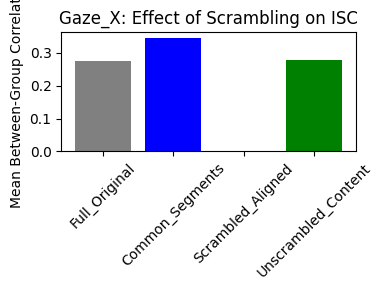

  Finished Gaze_X

Analyzing Signal: Gaze_Y


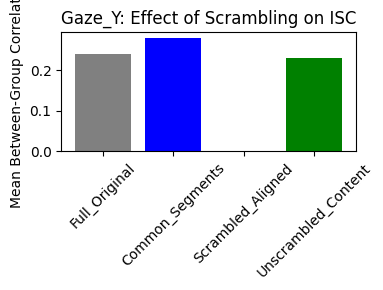

  Finished Gaze_Y

Analyzing Signal: Pupil_Mean


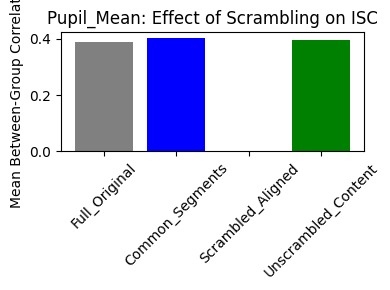

  Finished Pupil_Mean

Analyzing Signal: Heart_Rate


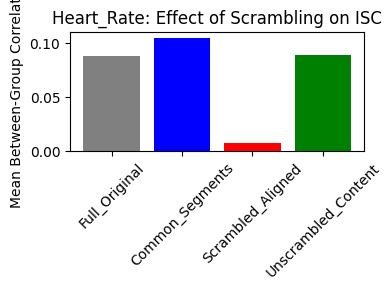

  Finished Heart_Rate

Analyzing Signal: GSR


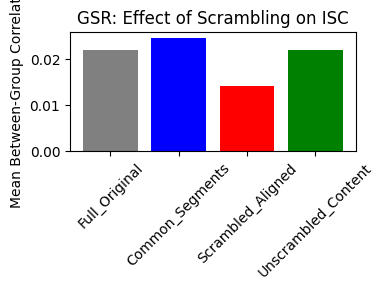

  Finished GSR


In [12]:
signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR' ]
if not os.path.exists(OUTPUT_DIR):
        os.makedirs(OUTPUT_DIR)
        
summary_report = ["# Segmented ISC Analysis Report\n"]
    
# 1. Load All Subjects
pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')
    

for signal in signals:
        print(f"\nAnalyzing Signal: {signal}")
        summary_report.append(f"\n## Signal: {signal}")
        
        signal_out_dir = os.path.join(OUTPUT_DIR, signal)
        if not os.path.exists(signal_out_dir): os.makedirs(signal_out_dir)
        
        try:
            df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
            df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
        except Exception as e:
            print(f"Error loading data for {signal}: {e}")
            continue
            
        # Ensure same length (trim to min)
        l_pc = df_pc.shape[0]
        l_pcm = df_pcm.shape[0]
        common_len = min(l_pc, l_pcm)
        
        df_pc = df_pc.iloc[:common_len]
        df_pcm = df_pcm.iloc[:common_len]
        
        # --- PREPARE DATASETS ---
        
        # A. Full Concatenated (Condition Blocks)
        # Combine [PC_subs, PCM_subs]
        df_full = pd.concat([df_pc, df_pcm], axis=1)
        
        # B. Segmented Chunks
        segs_pc  = utils.segment_isc_utils.extract_segments(df_pc, SEGMENTS['PC'], common_len)
        segs_pcm = utils.segment_isc_utils.extract_segments(df_pcm, SEGMENTS['PCM'], common_len)
        
        # C. Construct "Common" Data (1,2,5)
        # Concatenate time series of these segments
        common_pc  = pd.concat([segs_pc[1], segs_pc[2], segs_pc[5]], axis=0)
        common_pcm = pd.concat([segs_pcm[1], segs_pcm[2], segs_pcm[5]], axis=0)
        df_common  = pd.concat([common_pc, common_pcm], axis=1)
        
        # D. Construct "Scrambled (Aligned)" Data 
        # PC: 3+4 (Climax then Resolution)
        # PCM: 3+4 (Resolution then Climax) -> But compared by time idx
        scrambled_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        scrambled_pcm = pd.concat([segs_pcm[3], segs_pcm[4]], axis=0)
        # Note: They have slightly different lengths in time defs maybe? 
        # PC 3+4 = (38+35)=73s. PCM 3+4 = (35+38)=73s. Total len matches.
        # But boundaries might be slightly off in indices due to rounding.
        # We trim to min length to concatenate safely.
        min_len_sc    = min(scrambled_pc.shape[0], scrambled_pcm.shape[0])
        scrambled_pc  = scrambled_pc.iloc[:min_len_sc]
        scrambled_pcm = scrambled_pcm.iloc[:min_len_sc]
        
        df_scrambled  = pd.concat([scrambled_pc, scrambled_pcm], axis=1)

        # E. Construct "Unscrambled (Content)" Data
        # We want to match PC's sequence (1-2-3-4-5) with PCM's reordered sequence (1-2-[4]-[3]-5)
        # PC 3 (Climax) matches PCM 4 (Climax).
        # PC 4 (Resolution) matches PCM 3 (Resolution).
        
        # Reconstruct PCM as 1-2-4-3-5
        # Careful: PCM seg 4 is Climax. PCM seg 3 is Resolution.
        # PC seg 3 is Climax. PC seg 4 is Resolution.
        # So we want [PCM_1, PCM_2, PCM_4, PCM_3, PCM_5]
        
        unscrambled_pcm_parts = [segs_pcm[1], segs_pcm[2], segs_pcm[4], segs_pcm[3], segs_pcm[5]]
        unscrambled_pcm_ts    = pd.concat(unscrambled_pcm_parts, axis=0)
        
        # PC is just normal 1-2-3-4-5
        unscrambled_pc_ts = pd.concat([segs_pc[1], segs_pc[2], segs_pc[3], segs_pc[4], segs_pc[5]], axis=0)
        
        # Trim to match
        min_len_un         = min(unscrambled_pc_ts.shape[0], unscrambled_pcm_ts.shape[0])
        unscrambled_pc_ts  = unscrambled_pc_ts.iloc[:min_len_un]
        unscrambled_pcm_ts = unscrambled_pcm_ts.iloc[:min_len_un]
        
        df_unscrambled     = pd.concat([unscrambled_pc_ts, unscrambled_pcm_ts], axis=1)

        
        # --- ANALYSIS & PLOTTING ---
        
        datasets = {
            "Full_Original": df_full,
            "Common_Segments": df_common,
            "Scrambled_Aligned": df_scrambled,
            "Unscrambled_Content": df_unscrambled
        }
        
        isc_results = {}
        
        # 1. Block Matrices and Mean ISC
        for name, data in datasets.items():
            # Correlation Matrix
            corr = data.corr().values
            
            # Save Matrix Plot
            plt.figure(figsize=(5, 4))
            # Create labels: PC first then PCM
            # data columns are PC subs then PCM subs
            n_pc = df_pc.shape[1]
            n_pcm = df_pcm.shape[1]
            
            # Heatmap
            sns.heatmap(corr, center=0, cmap='RdBu_r', vmin=-0.5, vmax=0.5) # Capped for visibility
            
            # Draw lines separating conditions
            plt.axvline(n_pc, color='black', linewidth=1)
            plt.axhline(n_pc, color='black', linewidth=1)
            
            plt.title(f"{signal} - {name}")
            plt.tight_layout()
            #plt.show()
            plt.savefig(os.path.join(signal_out_dir, f"matrix_{name}.png"), dpi=300)
            plt.close()
            
            # Calculate Mean ISCs
            # 1. Within PC (Upper Tri)
            pc_block  = corr[:n_pc, :n_pc]
            within_pc = pc_block[np.triu_indices(n_pc, k=1)].mean()
            
            # 2. Within PCM
            pcm_block = corr[n_pc:, n_pc:]
            within_pcm = pcm_block[np.triu_indices(n_pcm, k=1)].mean()
            
            # 3. Between PC-PCM (Off-diagonal block)
            between_block = corr[:n_pc, n_pc:]
            between = between_block.mean()
            
            isc_results[name] = {
                'Within_PC': within_pc,
                'Within_PCM': within_pcm,
                'Between_Groups': between
            }
            summary_report.append(f"### {name}")
            summary_report.append(f"- Within PC: {within_pc:.3f}")
            summary_report.append(f"- Within PCM: {within_pcm:.3f}")
            summary_report.append(f"- Between Groups: {between:.3f}\n")

        # 2. Comparison Bar Plot
        # Compare "Between Groups" ISC across the conditions
        # Expected: Common > Scrambled. Unscrambled > Scrambled.
        
        names = list(isc_results.keys())
        betweens = [isc_results[n]['Between_Groups'] for n in names]
        
        plt.figure(figsize=(4, 3))
        bars = plt.bar(names, betweens, color=['gray', 'blue', 'red', 'green'])
        plt.ylabel("Mean Between-Group Correlation")
        plt.title(f"{signal}: Effect of Scrambling on ISC")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        #plt.savefig(os.path.join(signal_out_dir, "summary_between_isc.png"), dpi=300)
        plt.close()
        print(f"  Finished {signal}")

# Save summary
with open(os.path.join(OUTPUT_DIR, "segment_report.md"), "w") as f:
        f.writelines(summary_report)

In [13]:
import numpy as np
import pandas as pd
import os
import utils.segment_isc_utils # Assuming this is your module



signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')

# --- HELPER FUNCTION ---
def calculate_permuted_stats(df_a, df_b, n_permutations=2000):
    n_a, n_b = df_a.shape[1], df_b.shape[1]
    k_a, k_b = int(n_a // 2), int(n_b // 2)
    
    r_values = np.zeros(n_permutations)
    for i in range(n_permutations):
        idx_a = np.random.choice(n_a, k_a, replace=False)
        idx_b = np.random.choice(n_b, k_b, replace=False)
        g1 = df_a.iloc[:, idx_a].mean(axis=1)
        g2 = df_b.iloc[:, idx_b].mean(axis=1)
        r_values[i] = np.corrcoef(g1, g2)[0, 1]
    
    # Fisher Stats
    z_values = np.arctanh(np.clip(r_values, -0.999999, 0.999999))
    mean_z = np.mean(z_values)
    ci_lower_z = np.percentile(z_values, 2.5)
    ci_upper_z = np.percentile(z_values, 97.5)
    
    mean_r = np.tanh(mean_z)
    # Calculate error distances for plotting later
    err_low = mean_r - np.tanh(ci_lower_z)
    err_high = np.tanh(ci_upper_z) - mean_r
    
    return mean_r, err_low, err_high

# --- MAIN LOOP ---
if not os.path.exists(OUTPUT_DIR): os.makedirs(OUTPUT_DIR)
master_results = []

print("Running Permutation Analysis...")

for signal in signals:
    print(f"  Signal: {signal}")
    try:
        df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
        df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
        
        # Trim
        common_len = min(df_pc.shape[0], df_pcm.shape[0])
        df_pc = df_pc.iloc[:common_len]
        df_pcm = df_pcm.iloc[:common_len]
        
        # Extract
        segs_pc  = utils.segment_isc_utils.extract_segments(df_pc, SEGMENTS['PC'], common_len)
        segs_pcm = utils.segment_isc_utils.extract_segments(df_pcm, SEGMENTS['PCM'], common_len)

        # 1. Common
        d_com_pc  = pd.concat([segs_pc[1], segs_pc[2], segs_pc[5]], axis=0)
        d_com_pcm = pd.concat([segs_pcm[1], segs_pcm[2], segs_pcm[5]], axis=0)
        
        # 2. Scrambled (Time Aligned)
        d_scr_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        d_scr_pcm = pd.concat([segs_pcm[3], segs_pcm[4]], axis=0)
        min_s = min(d_scr_pc.shape[0], d_scr_pcm.shape[0])
        d_scr_pc, d_scr_pcm = d_scr_pc.iloc[:min_s], d_scr_pcm.iloc[:min_s]
        
        # 3. Unscrambled (Content Aligned)
        d_un_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        d_un_pcm = pd.concat([segs_pcm[4], segs_pcm[3]], axis=0)
        min_u = min(d_un_pc.shape[0], d_un_pcm.shape[0])
        d_un_pc, d_un_pcm = d_un_pc.iloc[:min_u], d_un_pcm.iloc[:min_u]
        
        # Calculate
        tasks = [("Common", d_com_pc, d_com_pcm),
                 ("Scrambled", d_scr_pc, d_scr_pcm),
                 ("Unscrambled", d_un_pc, d_un_pcm)]
        
        for cond, da, db in tasks:
            m, el, eh = calculate_permuted_stats(da, db)
            master_results.append({
                "Signal": signal,
                "Condition": cond,
                "Mean_r": m,
                "Err_Low": el,
                "Err_High": eh
            })
            
    except Exception as e:
        print(f"Error {signal}: {e}")

# --- SAVE ---
df_res = pd.DataFrame(master_results)
csv_path = os.path.join(OUTPUT_DIR, "isc_analysis_results.csv")
df_res.to_csv(csv_path, index=False)
print(f"Analysis saved to {csv_path}")

Running Permutation Analysis...
  Signal: Gaze_X
  Signal: Gaze_Y
  Signal: Pupil_Mean
  Signal: Heart_Rate
  Signal: GSR
Analysis saved to /Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/data/04_analysis/segmented/isc_analysis_results.csv


Plot saved to Final_ISC_Panel.png


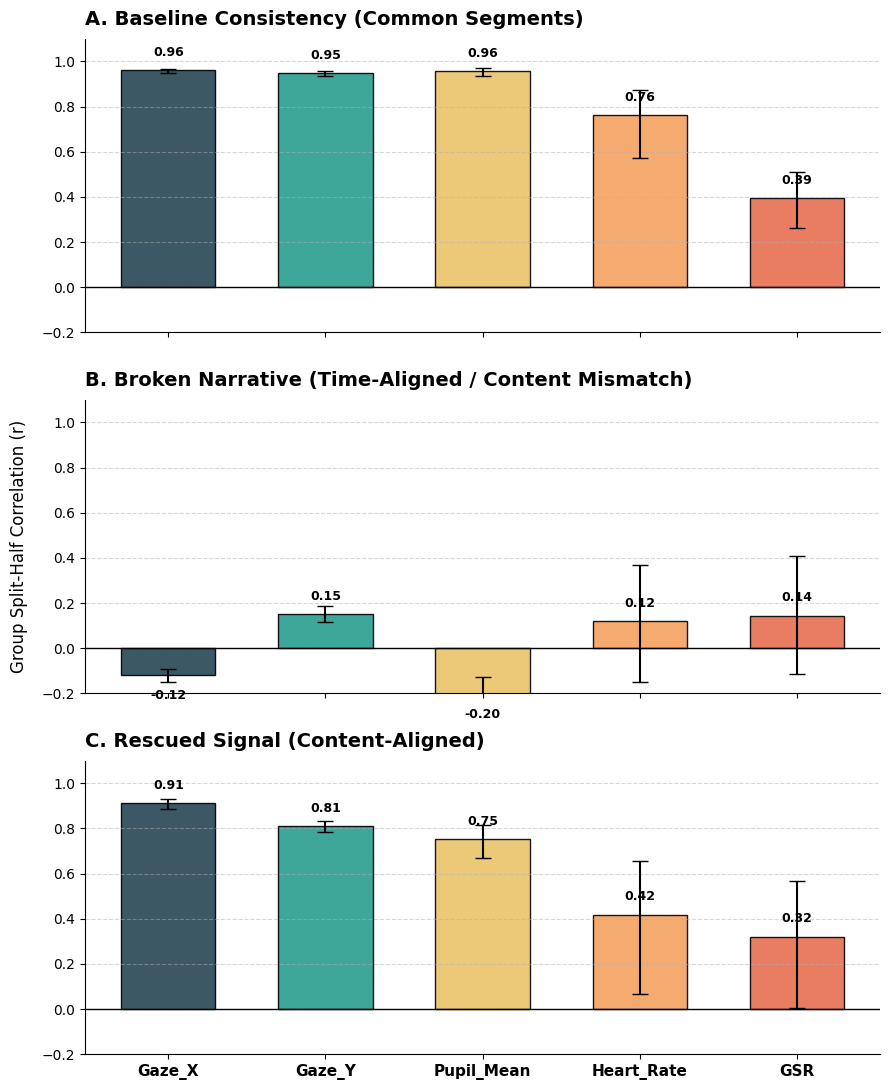

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

def plot_isc_panel(csv_path, output_path=None):
    # 1. Load Data
    df = pd.read_csv(csv_path)
    
    # 2. Enforce Ordering (Crucial for the Gradient visualization)
    # Define the order you want the bars to appear (High ISC -> Low ISC)
    signal_order = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
    condition_order = ["Common", "Scrambled", "Unscrambled"]
    
    # Convert to Categorical types for correct sorting
    df['Signal'] = pd.Categorical(df['Signal'], categories=signal_order, ordered=True)
    df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order, ordered=True)
    
    # Sort the dataframe so it plots in order
    df = df.sort_values(['Condition', 'Signal'])
    
    # 3. Aesthetics
    # Custom colors for the 5 signals
    # Options: 'Blues_r', 'Viridis', or custom hex
    colors = ['#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E76F51'] 
    
    titles = [
        "A. Baseline Consistency (Common Segments)",
        "B. Broken Narrative (Time-Aligned / Content Mismatch)",
        "C. Rescued Signal (Content-Aligned)"
    ]

    # 4. Plotting
    fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 11), sharex=True, sharey=True)
    
    for i, cond in enumerate(condition_order):
        ax = axes[i]
        subset = df[df['Condition'] == cond]
        
        x_indices = np.arange(len(signal_order))
        
        # Draw Bars
        bars = ax.bar(x_indices, subset['Mean_r'],
                      # Error bars expect shape (2, N) -> [Bottoms, Tops]
                      yerr=[subset['Err_Low'], subset['Err_High']],
                      capsize=6,
                      color=colors,
                      edgecolor='black',
                      linewidth=1,
                      alpha=0.9,
                      width=0.6)
        
        # Styling
        ax.set_title(titles[i], loc='left', fontsize=14, fontweight='bold', pad=10)
        ax.axhline(0, color='black', linewidth=1)
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        
        # Clean up borders (Despine)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(axis='y', labelsize=10)

        # Add Value Labels on bars
        for bar in bars:
            height = bar.get_height()
            # Position label slightly above/below bar depending on sign
            y_pos = height + 0.05 if height >= 0 else height - 0.12
            ax.text(bar.get_x() + bar.get_width()/2, y_pos,
                    f"{height:.2f}",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

    # 5. Final Layout
    # Set X-Axis labels only on the bottom plot
    axes[2].set_xticks(np.arange(len(signal_order)))
    axes[2].set_xticklabels(signal_order, fontsize=11, fontweight='bold')
    
    # Set Y-Axis Label for the middle plot (or all)
    axes[1].set_ylabel("Group Split-Half Correlation (r)", fontsize=12, labelpad=10)
    
    # Uniform Y-limits
    plt.ylim(-0.2, 1.1)
    plt.tight_layout()
    
    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to {output_path}")
    
    plt.show()

# --- RUN IT ---
csv_file = OUTPUT_DIR + "/isc_analysis_results.csv"
plot_isc_panel(csv_file, "Final_ISC_Panel.png")

In [17]:
### OLD

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Helper: Permuted Split-Half Between Groups ---
def calculate_permuted_stats(df_a, df_b, n_permutations=2000):
    """
    Returns: Mean r, lower_error_distance, upper_error_distance
    """
    n_a = df_a.shape[1]
    n_b = df_b.shape[1]
    k_a = int(n_a // 2)
    k_b = int(n_b // 2)
    
    if k_a < 1 or k_b < 1: return 0, 0, 0
    
    r_values = np.zeros(n_permutations)
    
    for i in range(n_permutations):
        idx_a = np.random.choice(n_a, k_a, replace=False)
        idx_b = np.random.choice(n_b, k_b, replace=False)
        g1 = df_a.iloc[:, idx_a].mean(axis=1)
        g2 = df_b.iloc[:, idx_b].mean(axis=1)
        r = np.corrcoef(g1, g2)[0, 1]
        r_values[i] = np.clip(r, -0.999999, 0.999999)

    # Fisher Z Statistics
    z_values = np.arctanh(r_values)
    mean_z = np.mean(z_values)
    ci_lower_z = np.percentile(z_values, 2.5)
    ci_upper_z = np.percentile(z_values, 97.5)
    
    mean_r = np.tanh(mean_z)
    ci_lower_r = np.tanh(ci_lower_z)
    ci_upper_r = np.tanh(ci_upper_z)
    
    # Return distances for Error Bars [Mean-Low, High-Mean]
    return mean_r, (mean_r - ci_lower_r), (ci_upper_r - mean_r)

# --- CONFIGURATION ---
signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
# Define colors for signals to maintain consistency across the 3 rows
signal_colors = ['#2F4F4F', '#556B2F', '#8FBC8F', '#CD5C5C', '#F08080'] 
# (Dark Slate, Olive, Sea Green, Indian Red, Light Coral) - Feel free to change!

if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

# Container for all results
master_results = []

print("Starting Analysis Loop...")

for signal in signals:
    print(f"  Processing {signal}...")
    
    try:
        # Load Data
        df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
        df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
        
        # Trim length
        common_len = min(df_pc.shape[0], df_pcm.shape[0])
        df_pc = df_pc.iloc[:common_len]
        df_pcm = df_pcm.iloc[:common_len]
        
        # Extract Segments
        segs_pc  = utils.segment_isc_utils.extract_segments(df_pc, SEGMENTS['PC'], common_len)
        segs_pcm = utils.segment_isc_utils.extract_segments(df_pcm, SEGMENTS['PCM'], common_len)

        # 1. COMMON (1,2,5)
        d_com_pc  = pd.concat([segs_pc[1], segs_pc[2], segs_pc[5]], axis=0)
        d_com_pcm = pd.concat([segs_pcm[1], segs_pcm[2], segs_pcm[5]], axis=0)
        
        # 2. SCRAMBLED (3,4 vs 3,4 Time-Aligned)
        d_scr_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        d_scr_pcm = pd.concat([segs_pcm[3], segs_pcm[4]], axis=0)
        min_s = min(d_scr_pc.shape[0], d_scr_pcm.shape[0])
        d_scr_pc = d_scr_pc.iloc[:min_s]
        d_scr_pcm = d_scr_pcm.iloc[:min_s]
        
        # 3. UNSCRAMBLED (3,4 vs 4,3 Content-Aligned)
        d_un_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        d_un_pcm = pd.concat([segs_pcm[4], segs_pcm[3]], axis=0) # Swapped
        min_u = min(d_un_pc.shape[0], d_un_pcm.shape[0])
        d_un_pc = d_un_pc.iloc[:min_u]
        d_un_pcm = d_un_pcm.iloc[:min_u]
        
        # Calculate Stats for all 3
        # Format: (ConditionName, DataA, DataB)
        tasks = [
            ("Common", d_com_pc, d_com_pcm),
            ("Scrambled", d_scr_pc, d_scr_pcm),
            ("Unscrambled", d_un_pc, d_un_pcm)
        ]
        
        for cond_name, da, db in tasks:
            mean, err_low, err_high = calculate_permuted_stats(da, db, n_permutations=2000)
            master_results.append({
                "Signal": signal,
                "Condition": cond_name,
                "Mean_r": mean,
                "Err_Low": err_low,
                "Err_High": err_high
            })
            
    except Exception as e:
        print(f"    Failed {signal}: {e}")

# --- MASTER PLOTTING ---
print("Generating Plots...")
df_res = pd.DataFrame(master_results)

# Enforce Signal Order (Gradient High -> Low)
df_res['Signal'] = pd.Categorical(df_res['Signal'], categories=signals, ordered=True)

# Create Subplots: 3 Rows (Conditions), 1 Column
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 12), sharex=True, sharey=True)

conditions_order = ["Common", "Scrambled", "Unscrambled"]
titles = [
    "1. Baseline Consistency (Common Segments)",
    "2. The 'Broken' Narrative (Scrambled Time-Alignment)",
    "3. The 'Rescued' Signal (Content-Alignment)"
]

for i, cond in enumerate(conditions_order):
    ax = axes[i]
    
    # Filter data for this condition
    subset = df_res[df_res['Condition'] == cond].sort_values('Signal')
    
    x_pos = np.arange(len(signals))
    
    # Plot Bars
    # We plot manually to handle the custom asymmetry of Fisher CI error bars perfectly
    bars = ax.bar(x_pos, subset['Mean_r'], 
                  yerr=[subset['Err_Low'], subset['Err_High']],
                  capsize=8, 
                  color=signal_colors, 
                  edgecolor='black', 
                  alpha=0.9,
                  width=0.7)
    
    # Aesthetics
    ax.set_title(titles[i], fontsize=14, loc='left', fontweight='bold')
    ax.set_ylabel("Split-Half Correlation (r)", fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.axhline(0, color='black', linewidth=1)
    
    # Add value labels on top of bars
    for bar in bars:
        height = bar.get_height()
        # Handle label position for negative bars
        offset = 0.05 if height >= 0 else -0.1
        ax.text(bar.get_x() + bar.get_width()/2., height + offset,
                f'{height:.2f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')

# Final X-Axis Formatting (only on bottom plot)
axes[2].set_xticks(np.arange(len(signals)))
axes[2].set_xticklabels(signals, fontsize=12, fontweight='bold')

# Set Y-Limit to make comparison easy (e.g., -0.1 to 1.0)
plt.ylim(-0.15, 1.05)

plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, "Master_ISC_Gradient_Panel.png")
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Master plot saved to: {save_path}")

In [9]:
### Plot